# 02 - Análise exploratória

**Pergunta:** quais características influenciam a popularidade de um jogo na Steam, e dá para prever essa popularidade com AM?

**Alvo:** `peak_ccu` (pico de jogadores simultâneos).

**Gera:** `data/processed/features.csv` (tabela limpa, usada na etapa de modelagem).

In [25]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path


sns.set_theme(style="darkgrid")
pd.set_option("display.max_columns", None)

dataset = pd.read_parquet("../data/clean/jogos_limpos.parquet")


### 2.1 -  Variável alvo: `peak_ccu`

In [26]:
p = dataset["peak_ccu"]
print(p.describe(percentiles=[.5,.75,.9,.95,.99,.999]).round(1).to_string)
print(f"\n== 0: {(p == 0).mean():.1%} | <= 5: {(p <= 5).mean():.1%} | >= 1000: {(p >= 1000).sum()} jogos")

<bound method Series.to_string of count      83646.0
mean          99.3
std         5914.5
min            0.0
50%            0.0
75%            0.0
90%            4.0
95%           21.0
99%          473.8
99.9%      15462.9
max      1362469.0
Name: peak_ccu, dtype: float64>

== 0: 77.7% | <= 5: 91.2% | >= 1000: 528 jogos


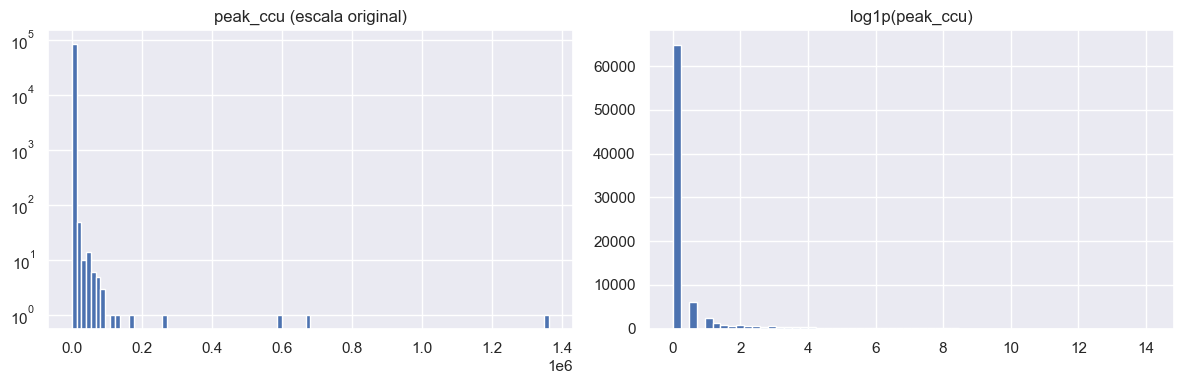

In [27]:


fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(p, bins=100); ax[0].set_title("peak_ccu (escala original)"); ax[0].set_yscale("log")
ax[1].hist(np.log1p(p), bins=60); ax[1].set_title("log1p(peak_ccu)")
plt.tight_layout(); plt.show()

A distribuição é extremamente assimétrica: a mediana é 0 e poucos jogos passam de milhares de jogadores. Regressão no valor bruto seria dominada por poucos outliers.
Por isso o alvo da modelagem será uma **classificação em faixas**, com regressão em `log1p(peak_ccu)` como análise complementar.

           jogos     %
faixa_ccu             
0          64966  77.7
1-20       14438  17.3
21-500      3435   4.1
500+         807   1.0


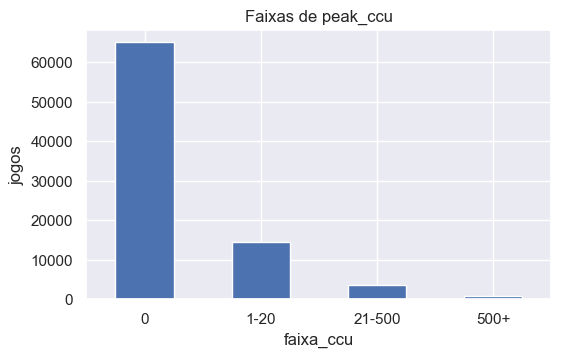

In [28]:
bins = [-1,0,20,500,np.inf]
labels = ["0", "1-20", "21-500", "500+"]
dataset["faixa_ccu"] = pd.cut(dataset.peak_ccu, bins=bins, labels=labels)
dataset["log_ccu"] = np.log1p(dataset.peak_ccu)
cont = dataset.faixa_ccu.value_counts().reindex(labels)
print(pd.DataFrame({"jogos": cont, "%": (cont / len(dataset) * 100).round(1)}))
ax = cont.plot(kind="bar", figsize=(6, 3.5), rot=0); ax.set_ylabel("jogos"); ax.set_title("Faixas de peak_ccu")
plt.show()





As classes são muito desbalanceadas (`0` domina e `500+` é cerca de 1%). Na modelagem: split estratificado, `class_weight` e F1-macro como métrica principal (acurácia sozinha seria enganosa).

### 2.2 - Engenharia de variáveis
Só características conhecidas **no lançamento** do jogo. A idade do jogo é calculada até a data de coleta (maio/2024), porque o `peak_ccu` é um retrato dessa data.

In [ ]:
def parse_list(x):
    try:
        v = ast.literal_eval(x)
        return v if isinstance(v, (list, dict)) else []
    except Exception:
        return []

data_coleta = pd.Timestamp("2024-05-31")
listas = {c: dataset[c].map(parse_list) for c in ["supported_languages", "full_audio_languages", "categories", "genres", "tags", "developers", "publishers"]}

x = pd.DataFrame({"AppID": dataset.AppID})
x = x.set_index("AppID")
x["preco"] = dataset.price
x["gratis"] = (dataset.price == 0).astype(bool)
x["idade_anos"] = (data_coleta - dataset.release_date).dt.days / 365.25
x["ano_lancamento"] = dataset.release_date.dt.year
x["mes_lancamento"] = dataset.release_date.dt.month
x["idade_minima"] = dataset.required_age
x["dlc"] = dataset.dlc_count
x["conquistas"] = dataset.achievements
x["mac"] = dataset.mac.astype(bool)
x["linux"] = dataset.linux.astype(bool)
x["n_idiomas"] = listas["supported_languages"].map(len)
x["tem_dublagem"] = (listas["full_audio_languages"].map(len) > 1).astype(bool)
x["n_categorias"] = listas["categories"].map(len)
x["n_generos"] = listas["genres"].map(len)
x["n_tags"] = listas["tags"].map(len)
x["tem_metacritic"] = dataset.metacritic_score.notna().astype(bool)
x["n_devs"] = listas["developers"].map(len)
x["autopublicado"] = [int(set(d) == set(p) and len(d) > 0) for d, p in zip(listas["developers"], listas["publishers"])]
x["log_ccu"] = dataset.log_ccu
x["faixa_ccu"] = dataset.faixa_ccu

y = pd.DataFrame(
    {
        "log_ccu": np.log1p(dataset["peak_ccu"].values),
        "faixa_ccu": pd.cut(
            dataset["peak_ccu"].values,
            bins=[-1, 0, 20, 500, np.inf],
            labels=["0", "1-20", "21-500", "500+"],
        ),
        "n_tags": dataset["tags"].map(len)
    },
    index=x.index,
)


flag = ["website", "support_url", "support_email", "notes","screenshots"]
for f in flag:
    x[f"tem_{f}"] = dataset[f"tem_{f}"]
print(x.shape)
x.describe().T[["mean", "50%", "max"]].round(2)




(83646, 25)


,mean,50%,max
preco,8.63,4.99,199.99
idade_anos,4.28,3.66,17.85
ano_lancamento,2019.62,2020.00,2024.00
mes_lancamento,6.75,7.00,12.00
idade_minima,0.43,0.00,18.00
dlc,0.66,0.00,57.00
conquistas,28.17,10.00,5394.00
n_idiomas,5.99,2.00,103.00
n_categorias,4.84,4.00,21.00
n_generos,2.90,3.00,9.00


## 2.3 - Distribuição e outliers das variáveis númericas


,outliers_IQR,max,p99,% outliers
preco,30,199.990000,49.99000,0.0
idade_anos,22,17.848049,14.86078,0.0
dlc,251,57.000000,13.00000,0.3
conquistas,70,5394.000000,167.34000,0.1
n_idiomas,91,103.000000,103.00000,0.1
n_categorias,69,21.000000,15.00000,0.1
n_generos,4,9.000000,6.00000,0.0
n_tags,0,20.000000,20.00000,0.0


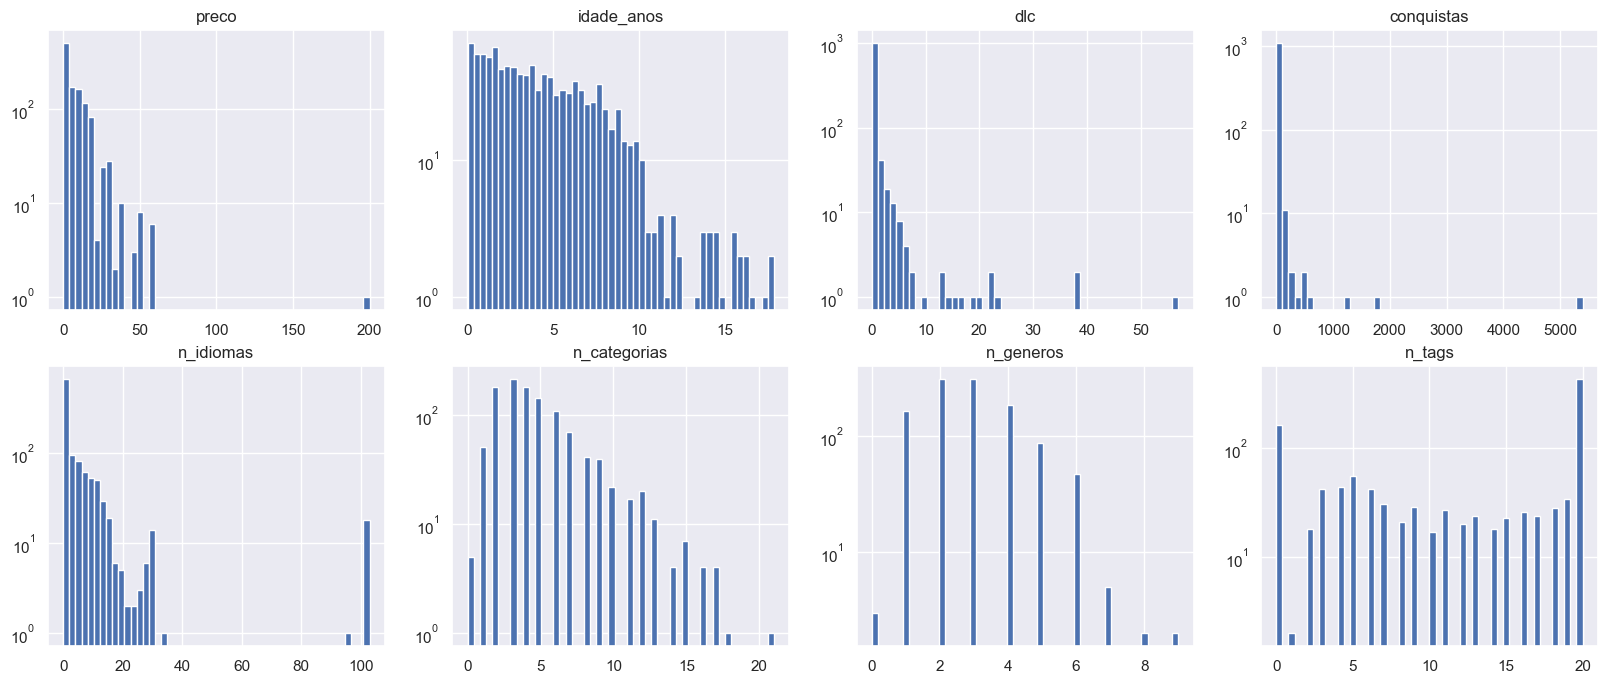

In [30]:
num = ["preco", "idade_anos", "dlc", "conquistas", "n_idiomas", "n_categorias", "n_generos", "n_tags"]
fig, axes = plt.subplots(2 ,4 ,figsize = (20,8))
for a, c in zip(axes.ravel(), num):
    a.hist(x[c].dropna(),bins=50)
    a.set_title(c) 
    a.set_yscale("log")

def n_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

out = pd.DataFrame({"outliers_IQR": {c: n_outliers(x[c].dropna()) for c in num},
                    "max": x[num].max(),
                    "p99": x[num].quantile(.99)})
out["% outliers"] = (out.outliers_IQR / len(x) * 100).round(1)


out

Quase todas as variáveis numéricas são assimétricas à direita. O IQR funciona mal com muitos zeros (em `dlc_count` o IQR é 0, então qualquer DLC vira "outlier"), então a contagem superestima. Os valores extremos são dados reais, não erros de coleta, e por isso não são removidos: os 5 jogos mais caros (US$ 300 a 1.000), por exemplo, têm 0 jogadores no pico. Nas variáveis de cauda longa aplica-se `log1p` antes da regressão logística e da MLP, e os modelos de árvore dispensam isso. Em `n_idiomas`, 985 jogos listam 103 idiomas e 91% deles têm 0 jogadores no pico, então foi criada a flag `todas_linguas`.

## 2.4- Relação das variáveis com a popularidade

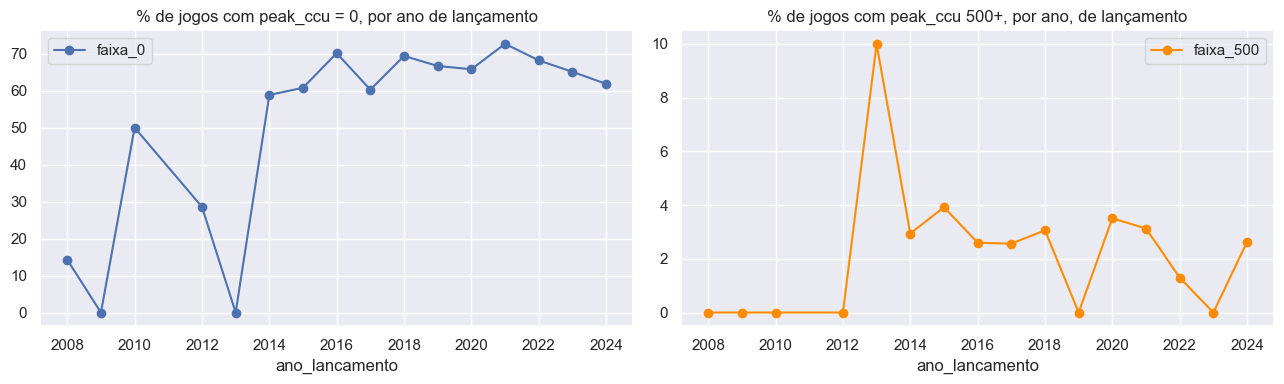

In [31]:
por_ano = x.groupby("ano_lancamento").agg(jogos=("log_ccu", "size"), faixa_500=("faixa_ccu", lambda s: (s == "500+").mean() * 100), faixa_0=("faixa_ccu", lambda s: (s == "0").mean() * 100))
por_ano = por_ano[por_ano.index >= 2008]


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
por_ano[["faixa_0"]].plot(ax=axes[0], marker="o"); axes[0].set_title("% de jogos com peak_ccu = 0, por ano de lançamento")
por_ano[["faixa_500"]].plot(ax=axes[1], marker="o", color="darkorange"); axes[1].set_title("% de jogos com peak_ccu 500+, por ano, de lançamento")
plt.tight_layout()
plt.show()


Jogos de 2012-2013 têm bem mais chance de ter jogadores (≈35% com pico 0) do que os de 2016 em diante (≈75-82%). Isso pode ser em parte **viés de sobrevivência**: o dataset é de maio/2024 e só contém jogos ainda na loja, então os antigos que fracassaram tendem a ter saído. Outra explicação possível é a **saturação da loja**, já que o número de lançamentos pequenos cresceu muito nos anos recentes. Com esses dados não dá para separar as duas causas, então o ano de lançamento deve ser lido como um indicador de contexto, e não como efeito direto sobre a popularidade.

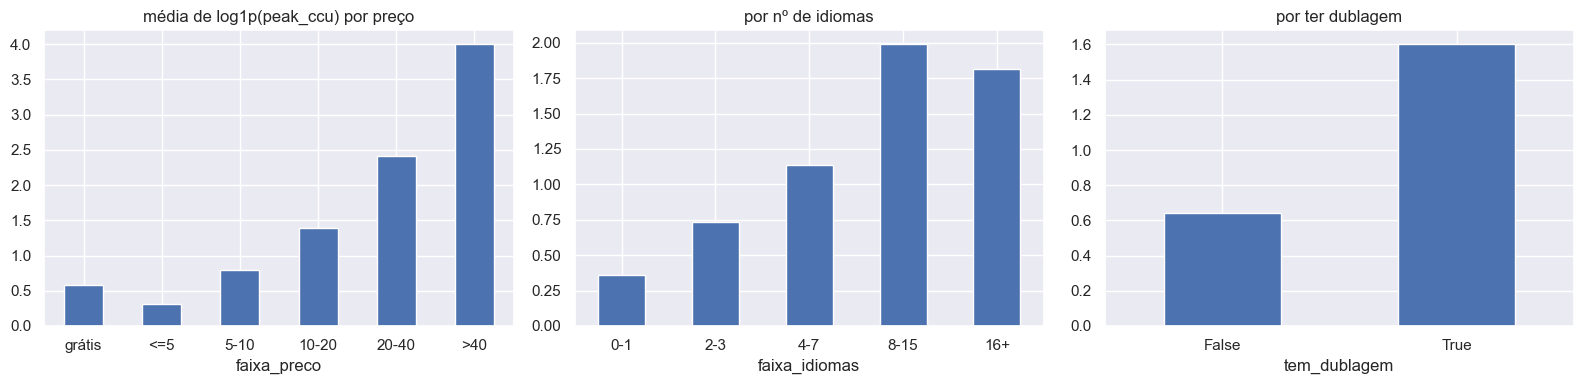

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x["faixa_preco"] = pd.cut(x.preco, [-1, 0, 5, 10, 20, 40, 1000], labels=["grátis", "<=5", "5-10", "10-20", "20-40", ">40"])
x["faixa_idiomas"] = pd.cut(x.n_idiomas, [-1, 1, 3, 7, 15, 200], labels=["0-1", "2-3", "4-7", "8-15", "16+"])

x.groupby("faixa_preco", observed=True).log_ccu.mean().plot(kind="bar", ax=axes[0], rot=0); axes[0].set_title("média de log1p(peak_ccu) por preço")
x.groupby("faixa_idiomas", observed=True).log_ccu.mean().plot(kind="bar", ax=axes[1], rot=0); axes[1].set_title("por nº de idiomas")
x.groupby("tem_dublagem").log_ccu.mean().plot(kind="bar", ax=axes[2], rot=0); axes[2].set_title("por ter dublagem")

plt.tight_layout() 
plt.show()

O pico médio de jogadores cresce com o preço: é maior nos jogos acima de US$ 40, e também nos jogos com dublagem e com 8 a 15 idiomas. A queda em 16+ idiomas coincide com o grupo de jogos que listam 103 idiomas, quase todos com 0 jogadores. Essas variáveis andam juntas (jogos de maior orçamento têm mais preço, idiomas e dublagem), então não dá para atribuir o efeito a cada uma isoladamente. Além disso, idiomas e dublagem são valores de maio/2024 e podem ser em parte consequência do sucesso do jogo.

In [33]:
flags = ["gratis", "mac", "linux", "tem_dublagem", "tem_website", "tem_metacritic", "autopublicado"]
tab = pd.DataFrame({f: {"% dos jogos": x[f].mean() * 100,
                        "% 500+ (com a flag)": (x.loc[x[f] == 1, "faixa_ccu"] == "500+").mean() * 100,
                        "% 500+ (sem a flag)": (x.loc[x[f] == 0, "faixa_ccu"] == "500+").mean() * 100} for f in flags}).T.round(1)
tab

,% dos jogos,% 500+ (com a flag),% 500+ (sem a flag)
gratis,19.5,1.8,2.1
mac,23.5,1.9,2.1
linux,15.9,2.2,2.0
tem_dublagem,23.2,5.8,0.9
tem_website,54.5,3.6,0.2
tem_metacritic,8.7,10.2,1.3
autopublicado,68.9,0.0,0.0


As flags ligadas a produção maior concentram os jogos de 500+: ter nota no Metacritic (8,6% contra 0,6%), dublagem (3,2% contra 0,5%) e site oficial (1,7% contra 0,3%). Jogos autopublicados fazem o inverso (0,6% contra 1,7%), e ser grátis, ter versão Mac ou Linux muda pouco. Essas flags andam juntas, então o efeito de cada uma não pode ser lido isoladamente, e sem controle por tamanho do jogo não dá para falar em causa

## 2.5 - Correlação e vazamentos

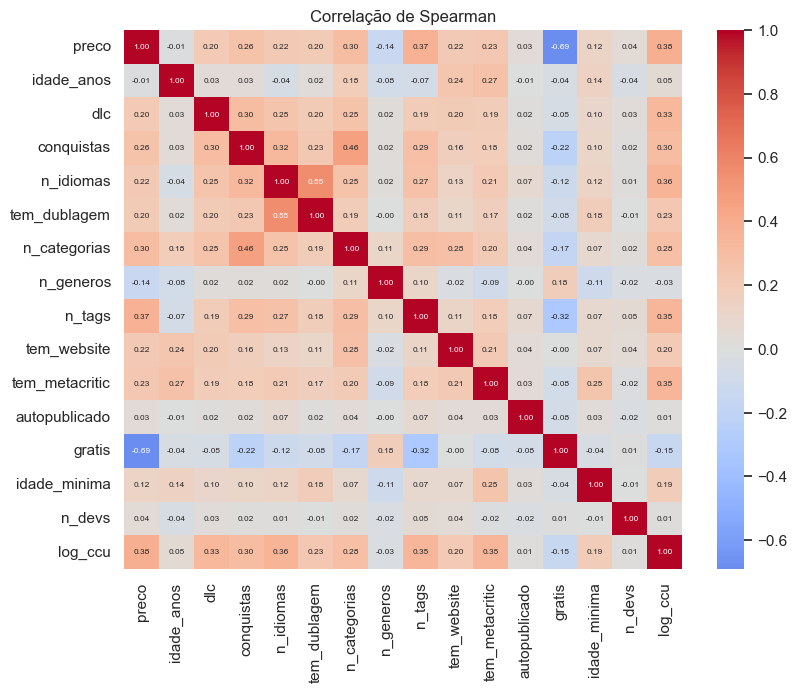

preco             0.383
n_idiomas         0.359
n_tags            0.350
tem_metacritic    0.347
dlc               0.327
conquistas        0.300
n_categorias      0.283
tem_dublagem      0.232
tem_website       0.204
idade_minima      0.192
idade_anos        0.052
n_devs            0.014
autopublicado     0.014
n_generos        -0.027
gratis           -0.153
Name: log_ccu, dtype: float64

In [34]:
feat = ["preco", "idade_anos", "dlc", "conquistas", "n_idiomas", "tem_dublagem", "n_categorias", "n_generos", "n_tags","tem_website", "tem_metacritic", "autopublicado", "gratis", "idade_minima", "n_devs"]
corr = x[feat + ["log_ccu"]].corr(method="spearman")
plt.figure(figsize=(9, 7)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 6}); plt.title("Correlação de Spearman"); plt.show()
corr["log_ccu"].drop("log_ccu").sort_values(ascending=False).round(3)

as correlações com o alvo são fracas a moderadas (máx. 0,31) e sem variável dominante, o que indica ausência de vazamento,
 mas também antecipa que a previsão será limitada, com ganho esperado dos modelos não lineares sobre o baseline.

### Gêneros

In [37]:
from collections import Counter

n_tags = listas["tags"].map(len)
exploracao = (
    x.drop(columns=["log_ccu", "faixa_ccu"], errors="ignore")
     .join(y)
     .assign(n_tags=n_tags.values)
)


generos = Counter(g for l in listas["genres"] for g in l)
top = [g for g, _ in generos.most_common(15)]
m = pd.DataFrame(
    {g: listas["genres"].map(lambda l: g in l).values for g in top},
    index=exploracao.index,
)

mais_comuns = pd.DataFrame({
    "jogos": m.sum(),
    "% 500+": [(exploracao.loc[m[g], "faixa_ccu"] == "500+").mean() * 100 for g in top],
    "% peak 0": [(exploracao.loc[m[g], "faixa_ccu"] == "0").mean() * 100 for g in top],
}).round(2).sort_values("% 500+", ascending=False)

print("geral: % 500+ =", round((exploracao.faixa_ccu == "500+").mean() * 100, 2),
      "| % peak 0 =", round((exploracao.faixa_ccu == "0").mean() * 100, 1))

mais_comuns

geral: % 500+ = 0.96 | % peak 0 = 77.7


,jogos,% 500+,% peak 0
Massively Multiplayer,2045,4.50,70.66
Design & Illustration,492,2.24,63.21
Utilities,827,2.18,63.97
Free to Play,7000,1.77,82.96
RPG,15080,1.64,70.26
Simulation,16910,1.53,71.50
Strategy,16321,1.46,71.50
Sports,3854,1.35,77.63
Action,34763,1.20,80.11
Early Access,8676,1.05,79.88


### Exclusão de `n_tags`

`n_tags` (nº de tags do jogo, máx. 20) tem mediana 9 nos jogos com pico 0 e 20 nas demais faixas, o que sugere que jogos sem jogadores recebem menos tags. Como a variável pode ser reflexo da popularidade e não causa dela, ficou fora das preditoras por precaução, assim como as colunas de avaliações. Ela é mantida apenas na análise exploratória.

**Teste de verificação (feito à parte):** para checar se `n_tags` entrega o alvo, treinamos um Random Forest (200 árvores, `class_weight="balanced"`) para prever a faixa de `peak_ccu`, com validação cruzada de 3 folds e F1-macro como métrica. Comparamos o mesmo conjunto de variáveis sem e com `n_tags`. O resultado foi 0,388 sem e 0,392 com, uma diferença de +0,004, dentro da margem de ruído. Não há evidência de que a variável entregue o alvo, e sua exclusão não prejudica o modelo.

## 2.6 - Salvando a tabela para a modelagem

In [43]:
saida = Path("../data/processed")
saida.mkdir(parents=True, exist_ok=True)

x = x.drop(columns=["log_ccu", "faixa_ccu", "n_tags"], errors="ignore")  # alvos estão em y; n_tags fica só na exploração

generos_top = [g for g, _ in generos.most_common(20)]
flags_generos = pd.DataFrame(
    {f"genero_{g}": listas["genres"].map(lambda l: g in l).values for g in generos_top},
    index=x.index,
)

final = x.drop(columns=["faixa_preco", "faixa_idiomas"], errors="ignore").join(y).join(flags_generos)

y.to_parquet(saida / "y.parquet" )

final.to_parquet(saida / "features.parquet")
print(final.shape, "->", saida / "features.parquet")

(83646, 45) -> ..\data\processed\features.parquet


## 8. Principais achados

1. **Alvo muito desbalanceado:** 77,7% dos jogos têm `peak_ccu` = 0 e só 1,0% passam de 500. Classificação em 4 faixas, F1-macro, split estratificado.
2. **Ano de lançamento:** jogos de 2012-2013 têm bem mais chance de ter jogadores (≈35% com pico 0) do que os de 2016 em diante (≈75-82%). Parte disso é viés de sobrevivência (só jogos antigos que ainda têm público seguem na loja) e parte é a saturação da loja nos anos recentes.
3. **Escala de produção:** mediana de preço sobe de 3,99 (faixa 0) para 19,99 (faixa 500+); idiomas de 1 para 11; conquistas de 0 para 42. Ter nota no Metacritic: 8,6% dos jogos com a flag chegam a 500+, contra 0,6% sem. Essas variáveis andam juntas (colinearidade).
4. **Idiomas:** a popularidade média cresce até 8-15 idiomas e cai na faixa 16+. Parte da queda vem de 985 jogos que listam 103 idiomas distintos, dos quais 91% têm pico 0 e nenhum chega a 500+; eles ganharam a flag `todas_linguas`.
5. **Gêneros:** Massively Multiplayer tem 4,5% em 500+ (média geral 0,96%); Indie (0,52%) e Casual (0,33%) ficam abaixo.
6. **Autopublicado** (dev = publisher, 69% dos jogos): 0,6% em 500+ contra 1,7%.
7. **Variáveis fora dos preditores:** avaliações, recomendações, tempo de jogo e `estimated_owners` (efeito da popularidade); `n_tags` (possível efeito da popularidade, excluída por precaução). `user_score` (100% zero), `windows` e `tem_suporte` (quase constantes) foram descartadas na limpeza.